Saving images.jpg to images (2).jpg


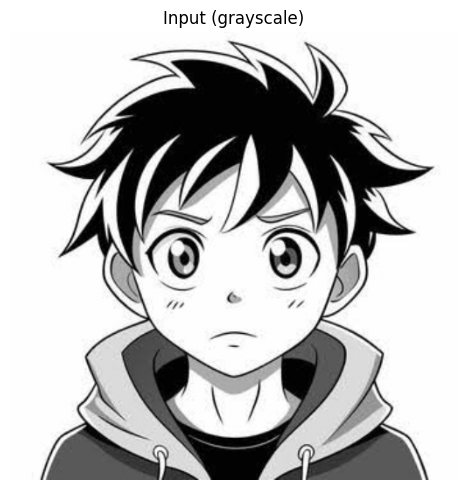

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
path = list(uploaded.keys())[0]
img_color = cv2.imread(path)
img = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)   # grayscale version used in all tasks
img = cv2.resize(img, (512, 512))                  # fixed size so two-image operations work

def show(images, titles, cols=3, save_as=None, figsize=(15, 9)):
  rows = int(np.ceil(len(images) / cols))
  plt.figure(figsize=figsize)
  for i, (im, t) in enumerate(zip(images, titles)):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t); plt.axis('off')
    plt.tight_layout()
    if save_as: plt.savefig(save_as, dpi=150)
  plt.show()

show([img], ["Input (grayscale)"], cols=1, figsize=(5, 5))

Manual and OpenCV results identical: False


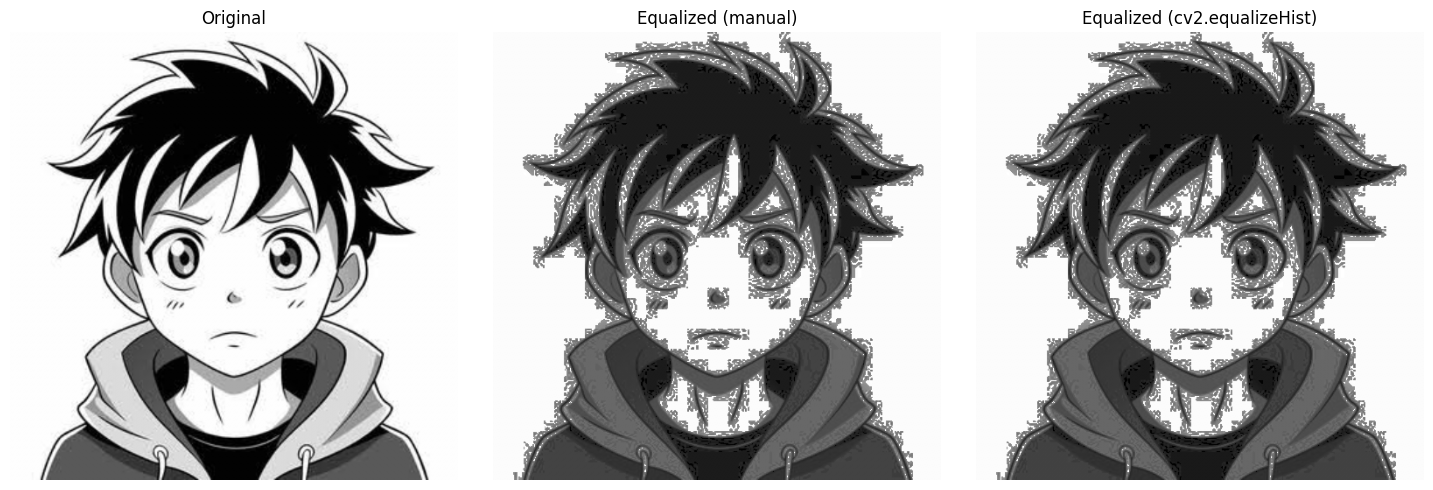

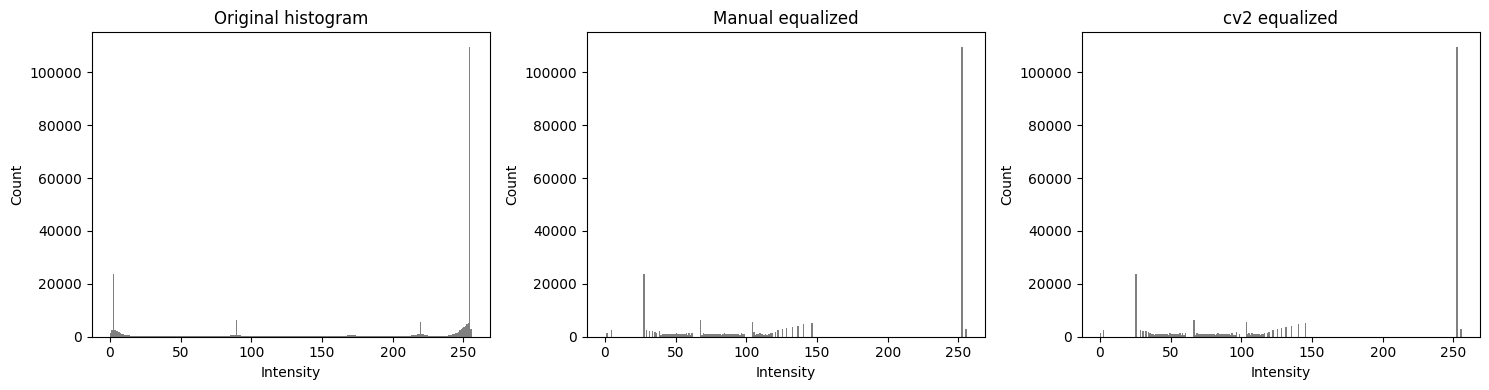

In [8]:
hist = np.bincount(img.ravel(), minlength=256)

pdf = hist / img.size

cdf = np.cumsum(pdf)

s = np.round(255 * cdf).astype(np.uint8)

eq_manual = s[img]

eq_cv = cv2.equalizeHist(img)

print(
    "Manual and OpenCV results identical:",
    np.array_equal(eq_manual, eq_cv)
)

show(
    [img, eq_manual, eq_cv],
    [
        "Original",
        "Equalized (manual)",
        "Equalized (cv2.equalizeHist)"
    ],
    save_as="task1_images.png",
    figsize=(15, 5)
)

plt.figure(figsize=(15, 4))

for i, (im, t) in enumerate(
    zip(
        [img, eq_manual, eq_cv],
        ["Original histogram", "Manual equalized", "cv2 equalized"]
    )
):
    plt.subplot(1, 3, i + 1)

    plt.hist(
        im.ravel(),
        bins=256,
        range=(0, 256),
        color='gray'
    )

    plt.title(t)
    plt.xlabel("Intensity")
    plt.ylabel("Count")

plt.tight_layout()

plt.savefig("task1_histograms.png", dpi=150)

plt.show()

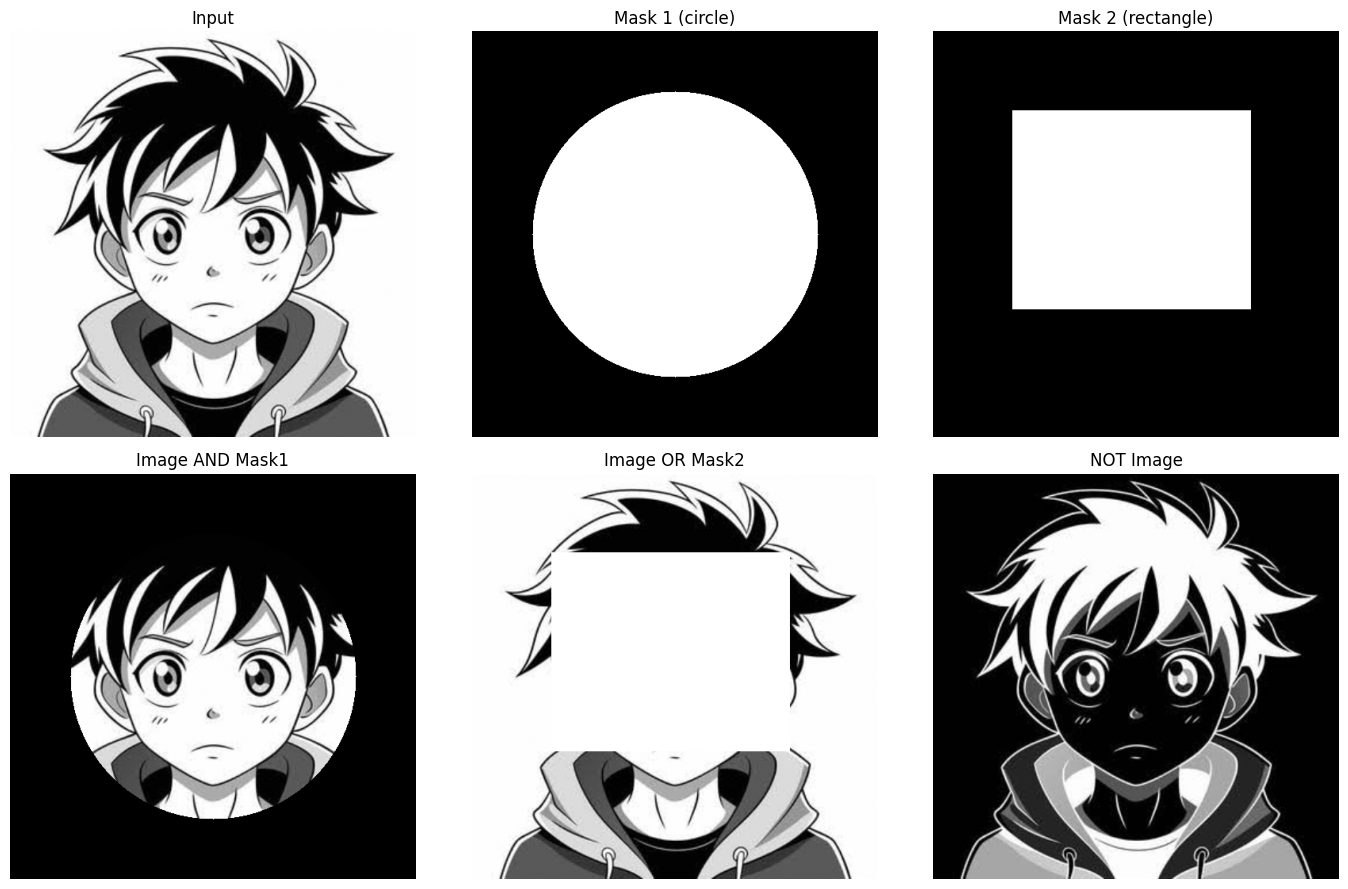

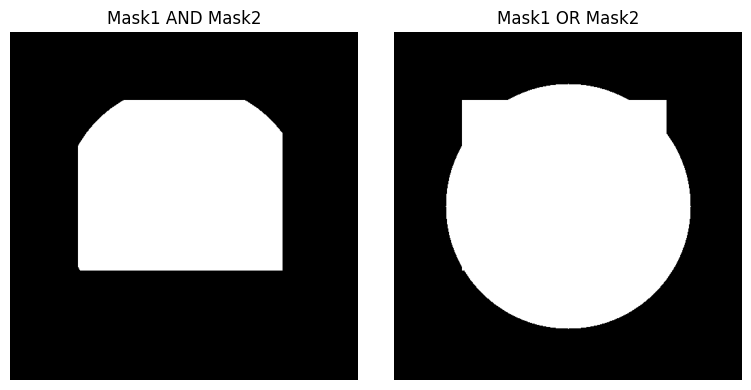

In [9]:
h, w = img.shape

mask1 = np.zeros((h, w), np.uint8)

cv2.circle(mask1, (w // 2, h // 2), 180, 255, -1)

mask2 = np.zeros((h, w), np.uint8)

cv2.rectangle(mask2, (100, 100), (400, 350), 255, -1)

and_res = cv2.bitwise_and(img, img, mask=mask1)

or_res = cv2.bitwise_or(img, mask2)

not_res = cv2.bitwise_not(img)

and_masks = cv2.bitwise_and(mask1, mask2)

or_masks = cv2.bitwise_or(mask1, mask2)

show(
    [img, mask1, mask2, and_res, or_res, not_res],
    [
        "Input",
        "Mask 1 (circle)",
        "Mask 2 (rectangle)",
        "Image AND Mask1",
        "Image OR Mask2",
        "NOT Image"
    ],
    cols=3,
    save_as="task2_logic.png"
)

show(
    [and_masks, or_masks],
    ["Mask1 AND Mask2", "Mask1 OR Mask2"],
    cols=2,
    figsize=(8, 4)
)

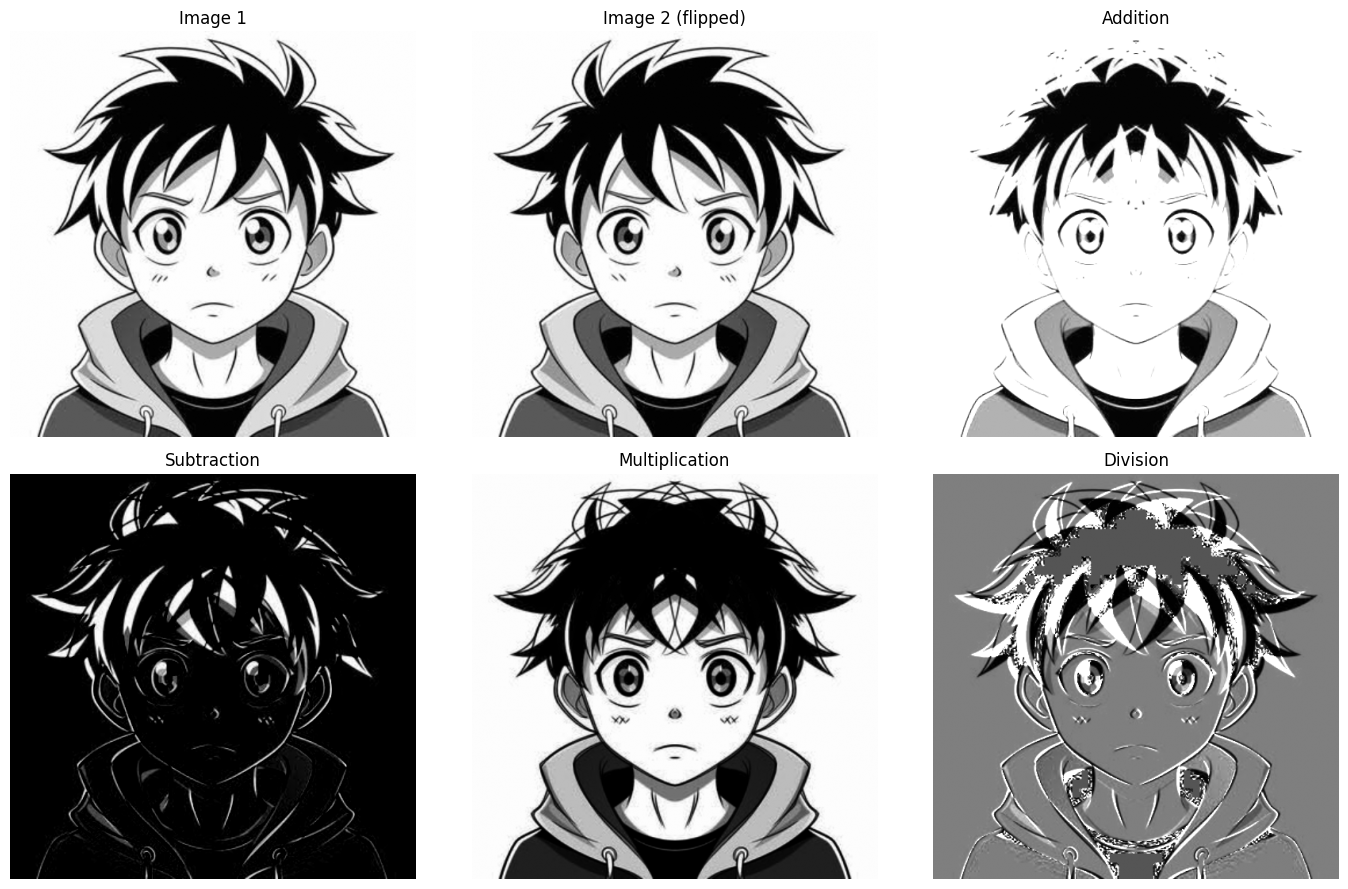

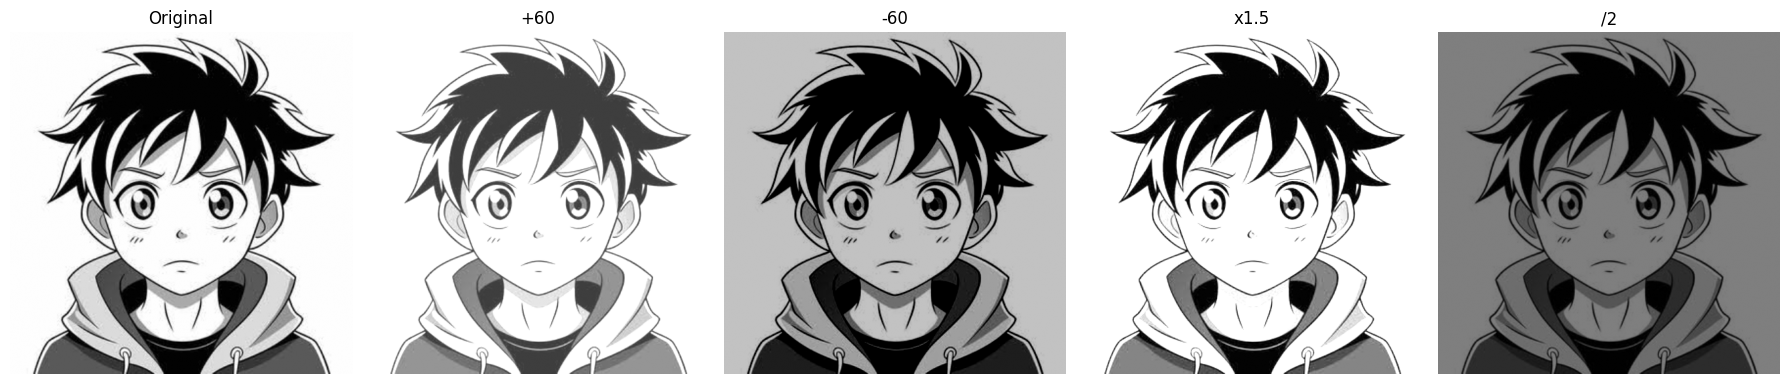

In [10]:
img2 = cv2.flip(img, 1)

add_res = cv2.add(img, img2)

sub_res = cv2.subtract(img, img2)

mul_res = np.clip(
    (img / 255.0) * (img2 / 255.0) * 255,
    0,
    255
).astype(np.uint8)

div_res = np.clip(
    img.astype(np.float32) / (img2.astype(np.float32) + 1) * 128,
    0,
    255
).astype(np.uint8)

show(
    [img, img2, add_res, sub_res, mul_res, div_res],
    [
        "Image 1",
        "Image 2 (flipped)",
        "Addition",
        "Subtraction",
        "Multiplication",
        "Division"
    ],
    cols=3,
    save_as="task3_arithmetic.png"
)

add_c = cv2.add(img, 60)

sub_c = cv2.subtract(img, 60)

mul_c = np.clip(
    img.astype(np.float32) * 1.5,
    0,
    255
).astype(np.uint8)

div_c = (img / 2).astype(np.uint8)

show(
    [img, add_c, sub_c, mul_c, div_c],
    ["Original", "+60", "-60", "x1.5", "/2"],
    cols=5,
    save_as="task3_constant.png",
    figsize=(18, 4)
)

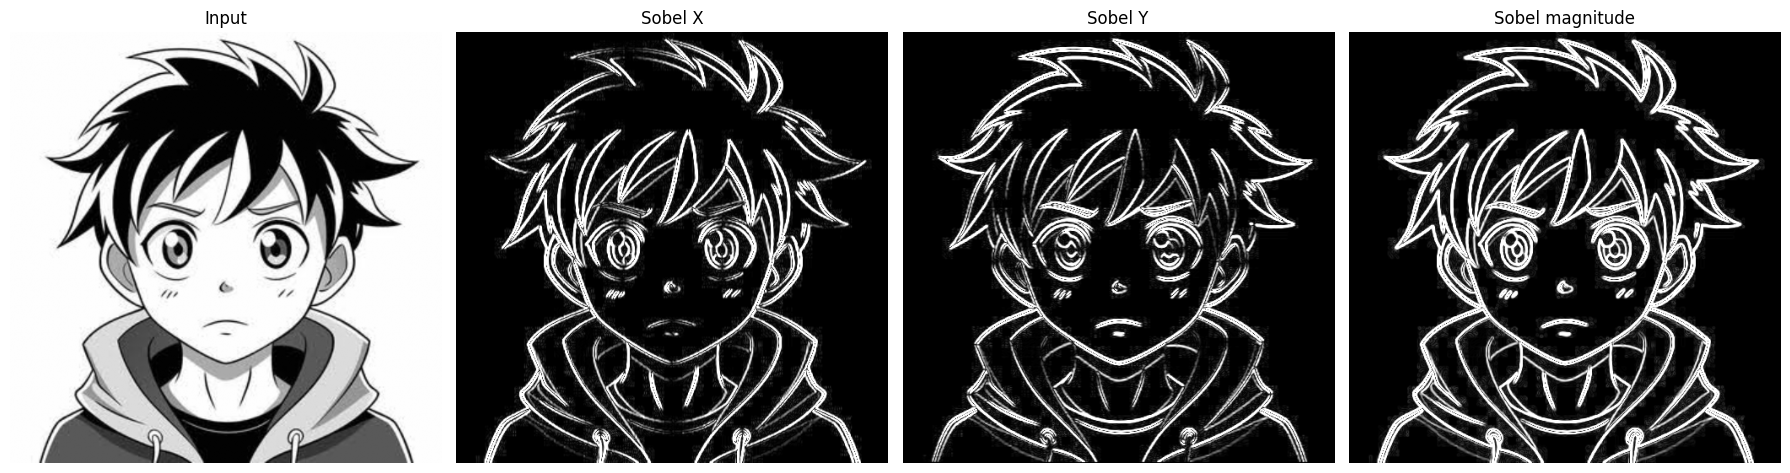

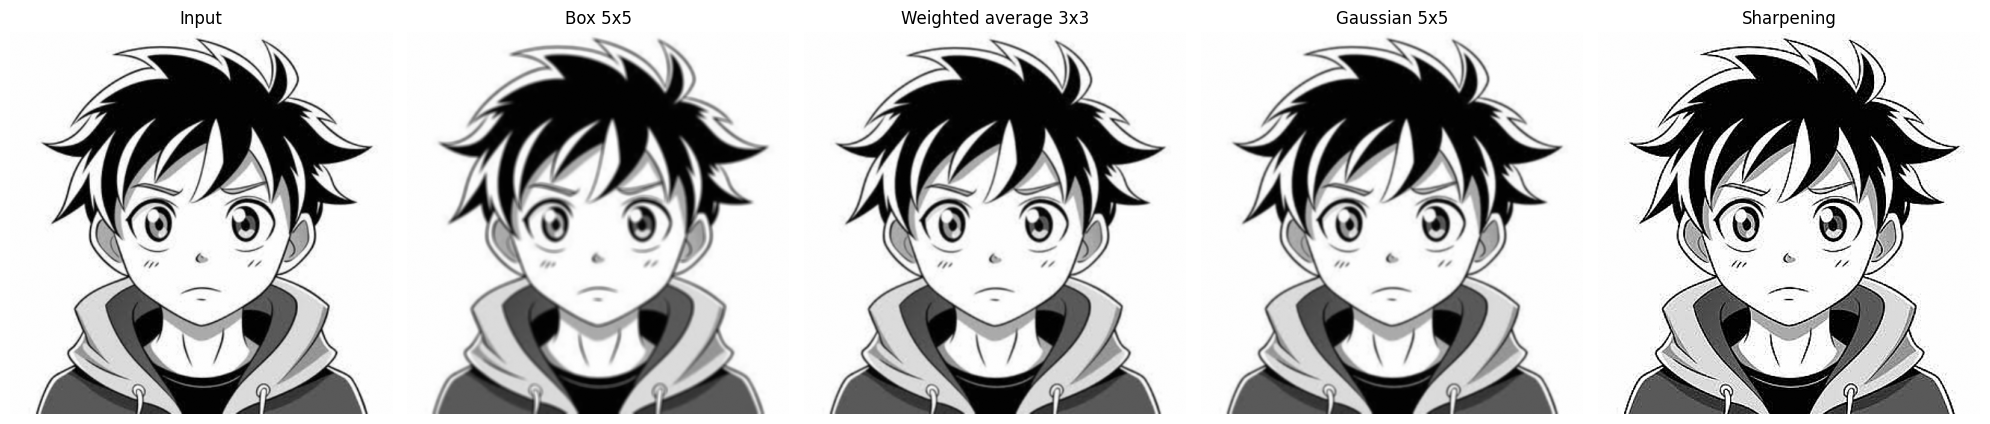

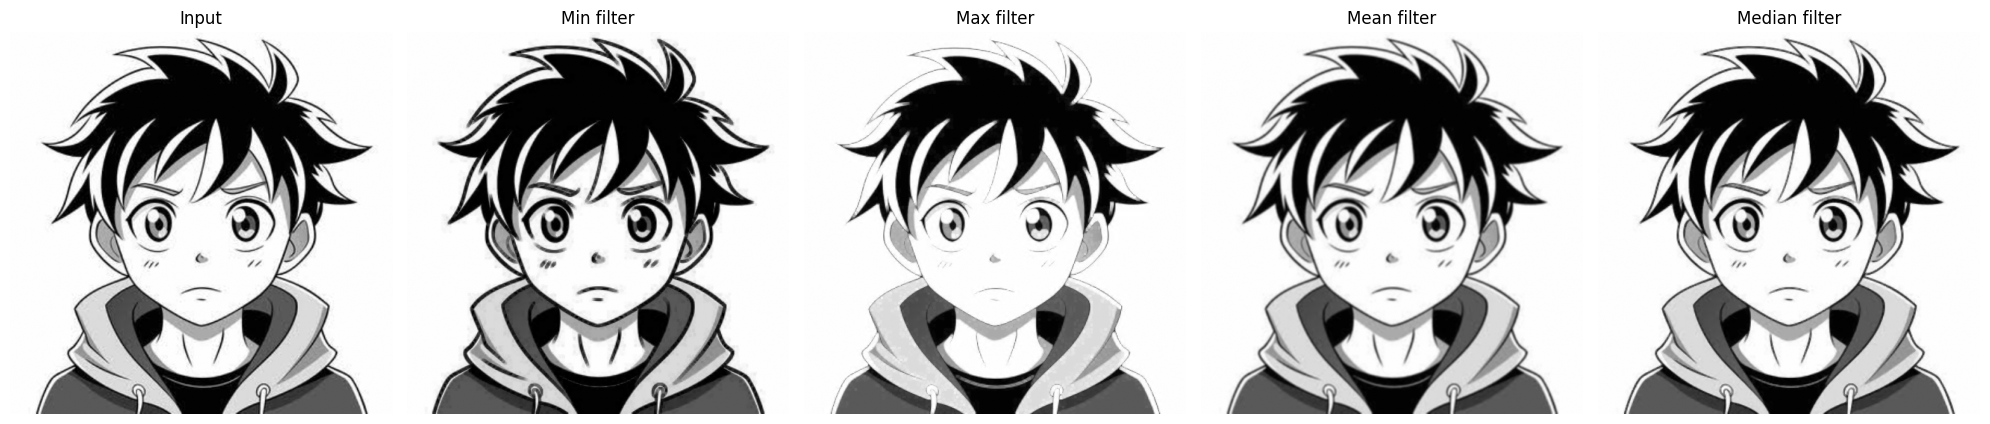

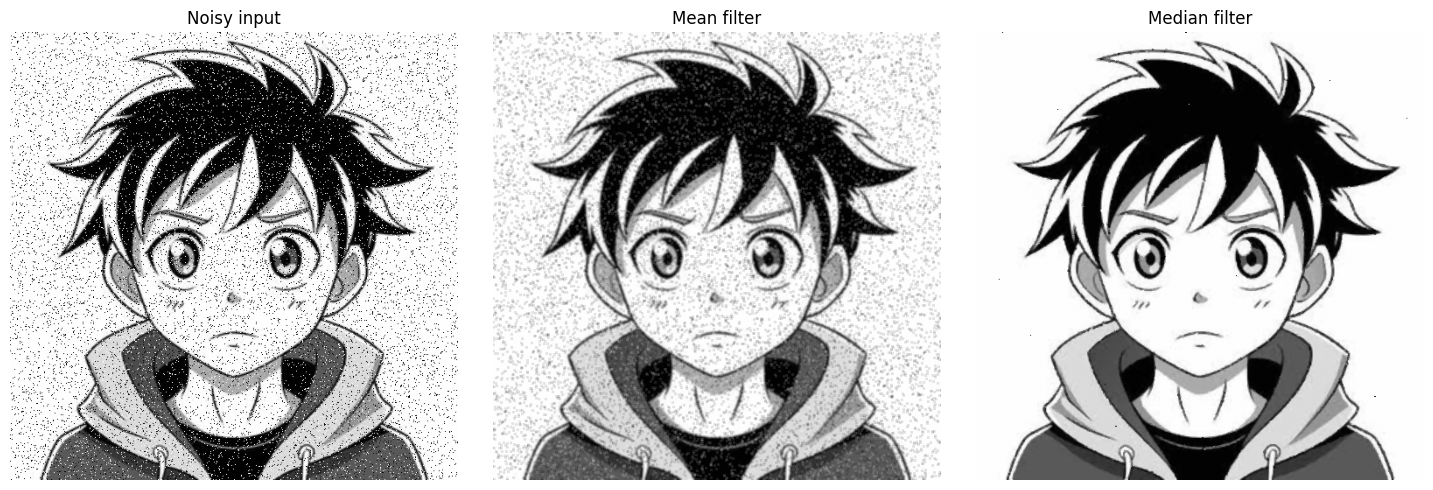

In [11]:
sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)

sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

sobel_mag = np.clip(
    np.sqrt(sobel_x**2 + sobel_y**2),
    0,
    255
).astype(np.uint8)

sobel_x_u8 = np.clip(
    np.abs(sobel_x),
    0,
    255
).astype(np.uint8)

sobel_y_u8 = np.clip(
    np.abs(sobel_y),
    0,
    255
).astype(np.uint8)

show(
    [img, sobel_x_u8, sobel_y_u8, sobel_mag],
    ["Input", "Sobel X", "Sobel Y", "Sobel magnitude"],
    cols=4,
    save_as="task4a_sobel.png",
    figsize=(18, 5)
)

box_k = np.ones((5, 5), np.float32) / 25

box = cv2.filter2D(img, -1, box_k)

wavg_k = np.array(
    [[1, 2, 1],
     [2, 4, 2],
     [1, 2, 1]],
    np.float32
) / 16

wavg = cv2.filter2D(img, -1, wavg_k)

g1d = cv2.getGaussianKernel(5, 1.0)

gauss_k = g1d @ g1d.T

gauss = cv2.filter2D(img, -1, gauss_k)

sharp_k = np.array(
    [[0, -1, 0],
     [-1, 5, -1],
     [0, -1, 0]],
    np.float32
)

sharp = cv2.filter2D(img, -1, sharp_k)

show(
    [img, box, wavg, gauss, sharp],
    [
        "Input",
        "Box 5x5",
        "Weighted average 3x3",
        "Gaussian 5x5",
        "Sharpening"
    ],
    cols=5,
    save_as="task4bcde.png",
    figsize=(20, 4.5)
)

k = np.ones((3, 3), np.uint8)

min_f = cv2.erode(img, k)

max_f = cv2.dilate(img, k)

mean_f = cv2.blur(img, (3, 3))

median_f = cv2.medianBlur(img, 3)

show(
    [img, min_f, max_f, mean_f, median_f],
    [
        "Input",
        "Min filter",
        "Max filter",
        "Mean filter",
        "Median filter"
    ],
    cols=5,
    save_as="task4f_order_stat.png",
    figsize=(20, 4.5)
)

noisy = img.copy()

rng = np.random.default_rng(0)

n = int(0.05 * img.size)

noisy[
    rng.integers(0, h, n),
    rng.integers(0, w, n)
] = 255

noisy[
    rng.integers(0, h, n),
    rng.integers(0, w, n)
] = 0

show(
    [
        noisy,
        cv2.blur(noisy, (3, 3)),
        cv2.medianBlur(noisy, 3)
    ],
    ["Noisy input", "Mean filter", "Median filter"],
    cols=3,
    save_as="task4f_noise.png",
    figsize=(15, 5)
)

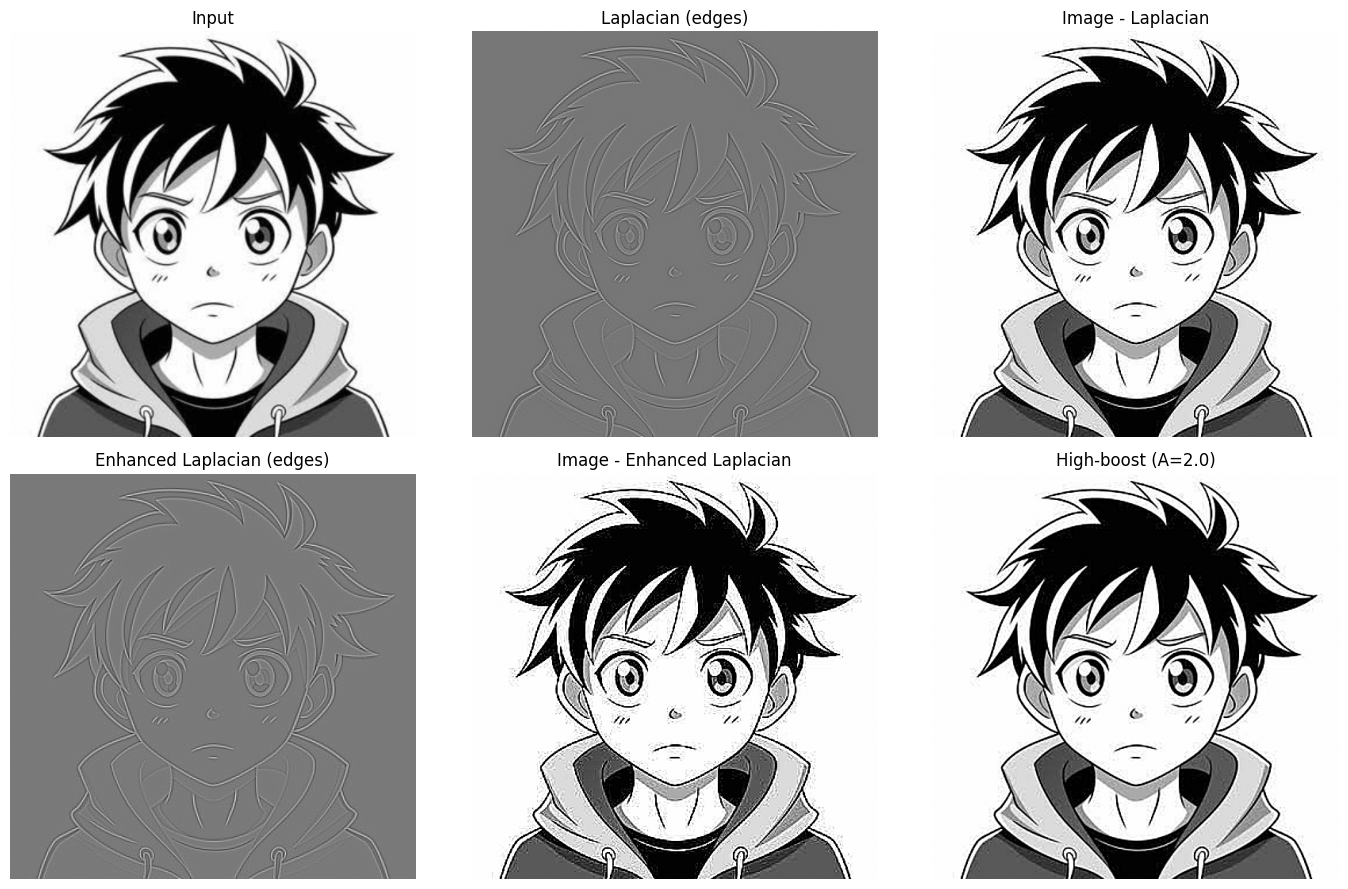

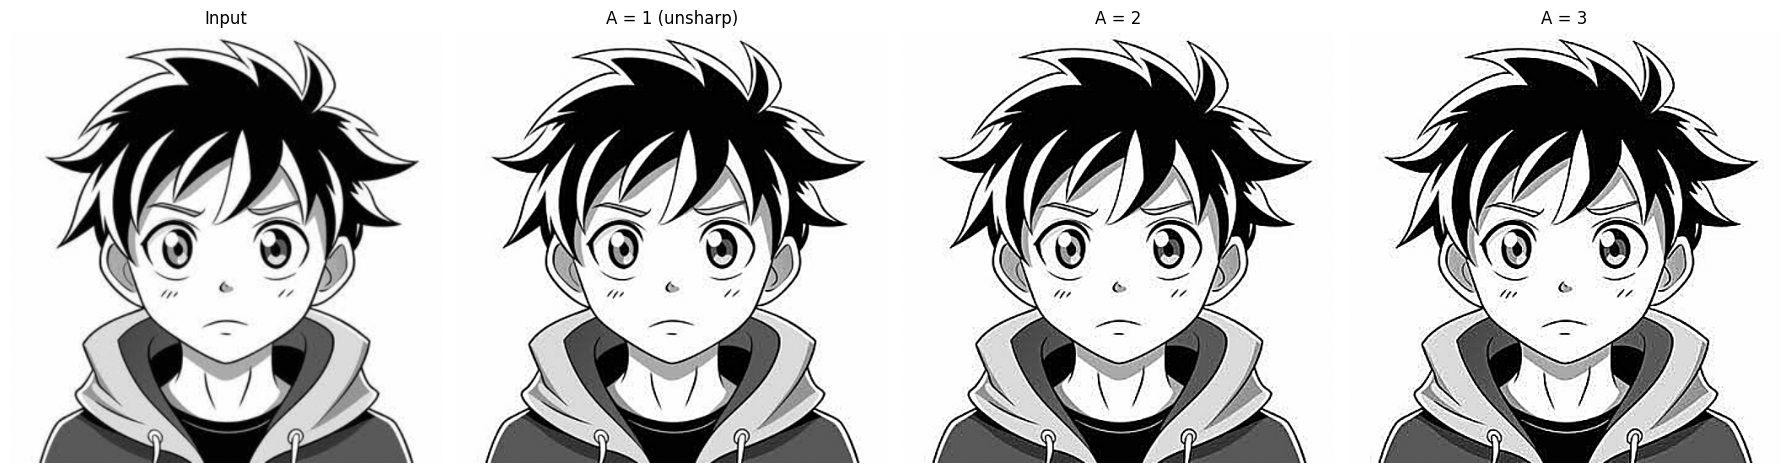

In [12]:
img_f = img.astype(np.float32)

lap_k = np.array(
    [[0, 1, 0],
     [1, -4, 1],
     [0, 1, 0]],
    np.float32
)

lap = cv2.filter2D(img_f, -1, lap_k)

lap_sharp = np.clip(img_f - lap, 0, 255).astype(np.uint8)

elap_k = np.array(
    [[1, 1, 1],
     [1, -8, 1],
     [1, 1, 1]],
    np.float32
)

elap = cv2.filter2D(img_f, -1, elap_k)

elap_sharp = np.clip(img_f - elap, 0, 255).astype(np.uint8)

blurred = cv2.GaussianBlur(img_f, (5, 5), 1.5)

unsharp_mask = img_f - blurred

A = 2.0

high_boost = np.clip(
    img_f + A * unsharp_mask,
    0,
    255
).astype(np.uint8)


def scale(x):
    x = x - x.min()
    return (255 * x / x.max()).astype(np.uint8)


show(
    [
        img,
        scale(lap),
        lap_sharp,
        scale(elap),
        elap_sharp,
        high_boost
    ],
    [
        "Input",
        "Laplacian (edges)",
        "Image - Laplacian",
        "Enhanced Laplacian (edges)",
        "Image - Enhanced Laplacian",
        f"High-boost (A={A})"
    ],
    cols=3,
    save_as="task5_laplacian.png"
)

show(
    [img] + [
        np.clip(img_f + a * unsharp_mask, 0, 255).astype(np.uint8)
        for a in (1, 2, 3)
    ],
    [
        "Input",
        "A = 1 (unsharp)",
        "A = 2",
        "A = 3"
    ],
    cols=4,
    save_as="task5_highboost_compare.png",
    figsize=(18, 5)
)